# Entrenamiento SARIMA: viajes reportados de Yellow Taxi

**Clase final de Data Science**  
Serie diaria univariada, baselines, selección temporal, pronóstico y diagnóstico.

> La variable objetivo cuenta **viajes reportados con recogida válida**. Su alcance corresponde a los registros presentes en estos archivos; estimar la demanda total, la demanda pendiente de atención o los viajes ausentes requiere evidencia adicional.

## 1. Entorno e importaciones

El notebook opera con recursos locales. Fijamos una semilla para favorecer la reproducibilidad, aunque los ajustes empleados son deterministas.

In [1]:
from pathlib import Path
import platform
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import statsmodels as sm
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller

SEED = 42
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.titlesize': 13})

print(f'Python: {platform.python_version()}')
print(f'pandas: {pd.__version__} | pyarrow: {pa.__version__}')
print(f'statsmodels: {sm.__version__}')

Python: 3.12.3
pandas: 3.0.5 | pyarrow: 25.0.0
statsmodels: 0.15.0


## 2. Procedencia, alcance y regla de validez

Se usan exclusivamente tres archivos Parquet locales de NYC Yellow Taxi: febrero, marzo y abril de 2026. Para minimizar memoria y E/S, `pyarrow` lee solo `tpep_pickup_datetime`.

Una recogida se considera válida para este análisis cuando dispone de marca temporal y pertenece al mes indicado por el nombre del archivo: intervalo semiabierto `[inicio del mes, inicio del mes siguiente)`. Esta regla concentra la serie en las marcas del mes correspondiente. El evento contado se define mediante la fecha de recogida; tarifa, distancia y cantidad de pasajeros quedan fuera de esta definición. Las marcas temporales son *naive* y se interpretan según la convención local del conjunto de origen.

In [2]:
start_dir = Path.cwd().resolve()
ROOT = next((path for path in (start_dir, *start_dir.parents) if (path / 'DATASETS').is_dir()), None)
assert ROOT is not None, 'La raíz del repositorio debe incluir el directorio DATASETS'
DATA_DIR = ROOT / 'DATASETS'
FILES = [DATA_DIR / f'yellow_tripdata_2026-{month:02d}.parquet' for month in (2, 3, 4)]
missing = [str(path) for path in FILES if not path.exists()]
assert len(missing) == 0, f'Archivos requeridos pendientes: {missing}'
print('Directorio de trabajo:', ROOT)
print('Archivos:', *[path.name for path in FILES], sep='\n- ')

Directorio de trabajo: /home/rafa/CLASES_DS_IA_UAP
Archivos:
- yellow_tripdata_2026-02.parquet
- yellow_tripdata_2026-03.parquet
- yellow_tripdata_2026-04.parquet


## 3. Lectura ligera y controles de calidad

Además del número de filas, revisamos valores nulos, extremos temporales y observaciones fuera del mes nominal. Los extremos permiten detectar anomalías históricas o desplazamientos de pocos minutos mediante la única columna requerida.

In [3]:
daily_parts = []
quality_rows = []

for path in FILES:
    period = pd.Period(path.stem[-7:], freq='M')
    month_start, next_month = period.start_time, (period + 1).start_time
    table = pq.read_table(path, columns=['tpep_pickup_datetime'])
    pickup = table.column('tpep_pickup_datetime').to_pandas()
    valid = pickup.notna() & pickup.ge(month_start) & pickup.lt(next_month)

    quality_rows.append({
        'archivo': path.name,
        'filas': len(pickup),
        'nulos': int(pickup.isna().sum()),
        'mínimo observado': pickup.min(),
        'máximo observado': pickup.max(),
        'válidos en mes': int(valid.sum()),
        'fuera de mes': int((pickup.notna() & ~valid).sum()),
    })
    daily_parts.append(pickup.loc[valid].dt.floor('D').value_counts())

quality = pd.DataFrame(quality_rows)
display(quality)
print(f'Columnas leídas por archivo: 1 de {pq.ParquetFile(FILES[0]).schema_arrow.names.__len__()}')

,archivo,filas,nulos,mínimo observado,máximo observado,válidos en mes,fuera de mes
0,yellow_tripdata_2026-02.parquet,3399866,0,2026-01-31 23:31:23,2026-03-01 00:51:48,3399850,16
1,yellow_tripdata_2026-03.parquet,3952451,0,2008-12-31 23:03:20,2026-04-01 00:06:25,3952432,19
2,yellow_tripdata_2026-04.parquet,3831240,0,2001-01-01 09:23:58,2026-05-01 00:01:28,3831228,12


Columnas leídas por archivo: 1 de 20


## 4. Agregación diaria regular

Sumamos recogidas válidas por fecha y reindexamos a frecuencia diaria. Un cero introducido por la reindexación representa «cero viajes reportados ese día». La cantidad de fechas ausentes antes del relleno permite distinguir esa representación de una fecha originalmente ausente.

In [4]:
observed_daily = pd.concat(daily_parts).groupby(level=0).sum().sort_index()
full_index = pd.date_range(observed_daily.index.min(), observed_daily.index.max(), freq='D')
missing_days = full_index.difference(observed_daily.index)
y = observed_daily.reindex(full_index, fill_value=0).astype('int64')
y.index.name = 'fecha'
y.name = 'viajes_reportados'

assert y.index.is_monotonic_increasing and y.index.is_unique
assert y.index.freqstr == 'D'
print(f'Cobertura: {y.index.min().date()} a {y.index.max().date()} ({len(y)} días)')
print(f'Días ausentes antes de regularizar: {len(missing_days)}')
print(f'Total de viajes reportados válidos: {y.sum():,}')
display(y.describe().to_frame().T.round(1))

Cobertura: 2026-02-01 a 2026-04-30 (89 días)
Días ausentes antes de regularizar: 0
Total de viajes reportados válidos: 11,183,510


,count,mean,std,min,25%,50%,75%,max
viajes_reportados,89.0,125657.4,18281.1,26039.0,115023.0,126695.0,136288.0,161081.0


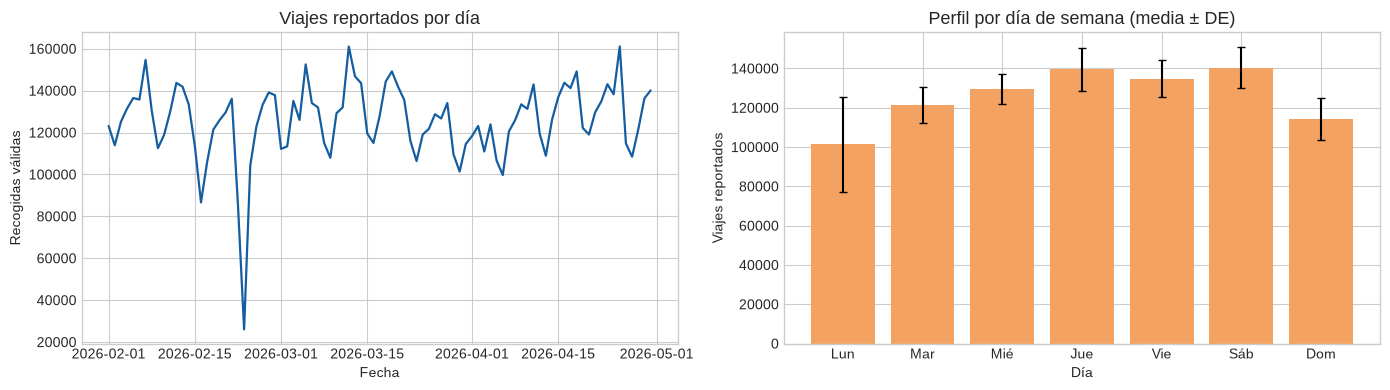

,mean,std
Lun,101494,24145
Mar,121366,9049
Mié,129393,7523
Jue,139554,10924
Vie,134796,9496
Sáb,140377,10458
Dom,114458,10687


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(y.index, y, color='#145DA0', linewidth=1.6)
axes[0].set(title='Viajes reportados por día', xlabel='Fecha', ylabel='Recogidas válidas')

day_names = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
dow = y.groupby(y.index.dayofweek).agg(['mean', 'std'])
axes[1].bar(day_names, dow['mean'], yerr=dow['std'], capsize=3, color='#F4A261')
axes[1].set(title='Perfil por día de semana (media ± DE)', xlabel='Día', ylabel='Viajes reportados')
plt.tight_layout()
plt.show()
display(dow.set_axis(day_names).round(0).astype(int))

## 5. Separación cronológica y baselines

Reservamos los 14 días finales y conservamos el orden temporal. Todo ajuste y la selección por AIC usan únicamente entrenamiento.

- **Último valor:** repite la última observación de entrenamiento.
- **Naive estacional, m=7:** repite cada valor de la última semana, respetando el día de semana.

Estos referentes simples son indispensables: un modelo más complejo solo aporta valor predictivo si los mejora fuera de muestra.

In [6]:
H = 14
train, test = y.iloc[:-H], y.iloc[-H:]
assert train.index.max() < test.index.min()

pred_last = pd.Series(train.iloc[-1], index=test.index, name='Último valor')
last_week = train.iloc[-7:].to_numpy()
pred_snaive = pd.Series(np.resize(last_week, H), index=test.index, name='Naive estacional m=7')

print(f'Entrenamiento: {train.index.min().date()} a {train.index.max().date()} ({len(train)} días)')
print(f'Prueba:        {test.index.min().date()} a {test.index.max().date()} ({len(test)} días)')

Entrenamiento: 2026-02-01 a 2026-04-16 (75 días)
Prueba:        2026-04-17 a 2026-04-30 (14 días)


## 6. ACF, PACF y diferenciación

La ACF/PACF se calcula solo con entrenamiento. Los picos en múltiplos de 7 y el perfil semanal justifican considerar una diferencia estacional `D=1, m=7`. También comparamos la serie original, una diferencia regular (`d=1`) y una estacional (`D=1`) mediante ADF como evidencia complementaria para la decisión.

Con apenas 75 días de entrenamiento, órdenes altos serían frágiles. Por ello se restringe la búsqueda a componentes AR/MA 0 o 1, con una sola diferencia como máximo.

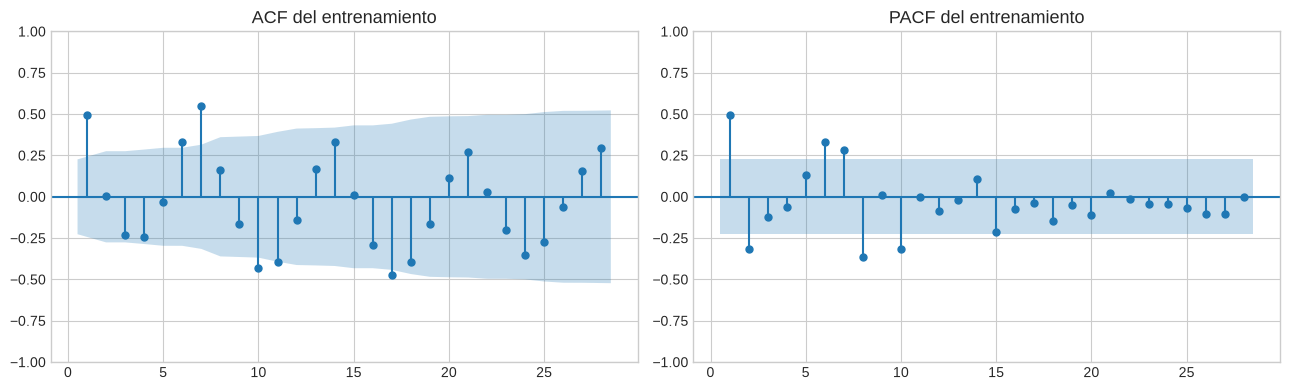

,estadístico ADF,p-valor,rezagos,n
transformación,,,,
Nivel,-2.8255,0.0547,9,65
Diferencia regular d=1,-3.9223,0.0019,6,67
"Diferencia estacional D=1, m=7",-2.4449,0.1295,7,60


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(train, lags=28, ax=axes[0], zero=False)
plot_pacf(train, lags=28, ax=axes[1], zero=False, method='ywm')
axes[0].set_title('ACF del entrenamiento')
axes[1].set_title('PACF del entrenamiento')
plt.tight_layout()
plt.show()

transforms = {
    'Nivel': train,
    'Diferencia regular d=1': train.diff().dropna(),
    'Diferencia estacional D=1, m=7': train.diff(7).dropna(),
}
adf_rows = []
for label, series in transforms.items():
    adf_result = adfuller(series, autolag='AIC', result_object=True)
    adf_rows.append({'transformación': label, 'estadístico ADF': adf_result.statistic, 'p-valor': adf_result.pvalue, 'rezagos': adf_result.lags, 'n': adf_result.nobs})
display(pd.DataFrame(adf_rows).set_index('transformación').round(4))

## 7. Candidatos SARIMA parsimoniosos

Ajustamos cuatro especificaciones predefinidas. Todas representan la estacionalidad semanal y alternan una diferencia regular y un término corto AR o MA. El intercepto corresponde a `d=0`, mientras que `d=1` usa una especificación de deriva nula. Elegimos el menor AIC **en entrenamiento**. El test se reserva hasta fijar el modelo.

In [8]:
candidates = [
    ((0, 0, 1), (0, 1, 1, 7)),
    ((1, 0, 0), (0, 1, 1, 7)),
    ((0, 1, 1), (0, 1, 1, 7)),
    ((1, 1, 0), (0, 1, 1, 7)),
]
fits = {}
fit_rows = []

for order, seasonal_order in candidates:
    label = f'SARIMA{order}x{seasonal_order}'
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        result = SARIMAX(
            train, order=order, seasonal_order=seasonal_order,
            trend='c' if order[1] == 0 else 'n',
            enforce_stationarity=False, enforce_invertibility=False,
        ).fit(disp=False, maxiter=150)
    fits[label] = result
    fit_rows.append({
        'modelo': label, 'AIC entrenamiento': result.aic,
        'convergió': bool(result.mle_retvals.get('converged', False)),
        'avisos': len(caught), 'segundos': time.perf_counter() - started,
    })

fit_table = pd.DataFrame(fit_rows).sort_values('AIC entrenamiento').reset_index(drop=True)
display(fit_table.round({'AIC entrenamiento': 2, 'segundos': 3}))
best_label = fit_table.loc[0, 'modelo']
best_fit = fits[best_label]
print('Seleccionado exclusivamente con entrenamiento:', best_label)

,modelo,AIC entrenamiento,convergió,avisos,segundos
0,"SARIMA(0, 1, 1)x(0, 1, 1, 7)",1287.84,True,0,0.087
1,"SARIMA(0, 0, 1)x(0, 1, 1, 7)",1302.41,True,0,0.060
2,"SARIMA(1, 1, 0)x(0, 1, 1, 7)",1312.94,True,0,0.052
3,"SARIMA(1, 0, 0)x(0, 1, 1, 7)",1324.05,True,0,0.081


Seleccionado exclusivamente con entrenamiento: SARIMA(0, 1, 1)x(0, 1, 1, 7)


## 8. Pronóstico, intervalos al 90 % y métricas

El intervalo expresa incertidumbre del modelo condicional a sus supuestos y a la serie histórica. Representar cambios de política, clima, eventos, errores de registro o incertidumbre sobre viajes ausentes requiere variables y evidencia adicionales.

Además de MAE y RMSE, usamos **MASE estacional con `m=7`**. Su escala es el MAE del naive estacional de una semana calculado solo dentro del entrenamiento original. Por tanto, `MASE < 1` mejora ese referente in-sample y `MASE > 1` presenta mayor error. La misma escala se conserva en las comparaciones fija y walk-forward para asegurar valores comparables y mantener el test reservado para la evaluación.

Escala MASE estacional m=7, solo entrenamiento: 11,592.3 viajes/día


,MAE,RMSE,MASE
Naive estacional m=7,5300.9,7058.6,0.457
SARIMA seleccionado,9388.8,11471.1,0.810
Último valor,14185.7,17683.7,1.224


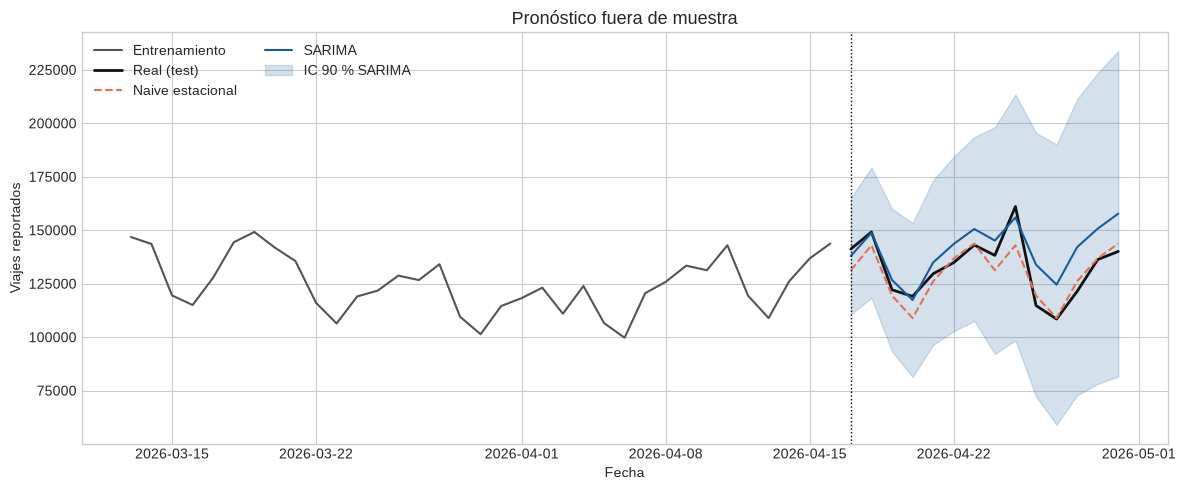

In [9]:
forecast = best_fit.get_forecast(steps=H)
pred_sarima = forecast.predicted_mean.rename('SARIMA seleccionado')
interval = forecast.conf_int(alpha=0.10)
interval.index = test.index
pred_sarima.index = test.index

MASE_M = 7
train_values = train.to_numpy()
mase_scale = np.mean(np.abs(train_values[MASE_M:] - train_values[:-MASE_M]))
assert np.isfinite(mase_scale) and mase_scale > 0
print(f'Escala MASE estacional m={MASE_M}, solo entrenamiento: {mase_scale:,.1f} viajes/día')

def metrics(actual, predicted, scale=mase_scale):
    error = np.asarray(actual) - np.asarray(predicted)
    mae = np.mean(np.abs(error))
    return {'MAE': mae, 'RMSE': np.sqrt(np.mean(error**2)), 'MASE': mae / scale}

predictions = {
    'Último valor': pred_last,
    'Naive estacional m=7': pred_snaive,
    'SARIMA seleccionado': pred_sarima,
}
score_table = pd.DataFrame({name: metrics(test, pred) for name, pred in predictions.items()}).T
display(score_table.sort_values('MAE').round({'MAE': 1, 'RMSE': 1, 'MASE': 3}))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train.index[-35:], train.iloc[-35:], label='Entrenamiento', color='#555555')
ax.plot(test.index, test, label='Real (test)', color='#111111', linewidth=2)
ax.plot(test.index, pred_snaive, label='Naive estacional', linestyle='--', color='#E76F51')
ax.plot(test.index, pred_sarima, label='SARIMA', color='#145DA0')
ax.fill_between(test.index, interval.iloc[:, 0], interval.iloc[:, 1], color='#145DA0', alpha=0.18, label='IC 90 % SARIMA')
ax.axvline(test.index.min(), color='black', linestyle=':', linewidth=1)
ax.set(title='Pronóstico fuera de muestra', xlabel='Fecha', ylabel='Viajes reportados')
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## 9. Diagnóstico de residuos

Buscamos residuos centrados, con patrón temporal aleatorio y autocorrelaciones compatibles con ruido blanco. Ljung–Box evalúa conjuntamente autocorrelaciones hasta cada rezago; p-valores pequeños aportan evidencia frente a la hipótesis de ruido blanco. La normalidad y la causalidad requieren pruebas y diseños específicos adicionales.

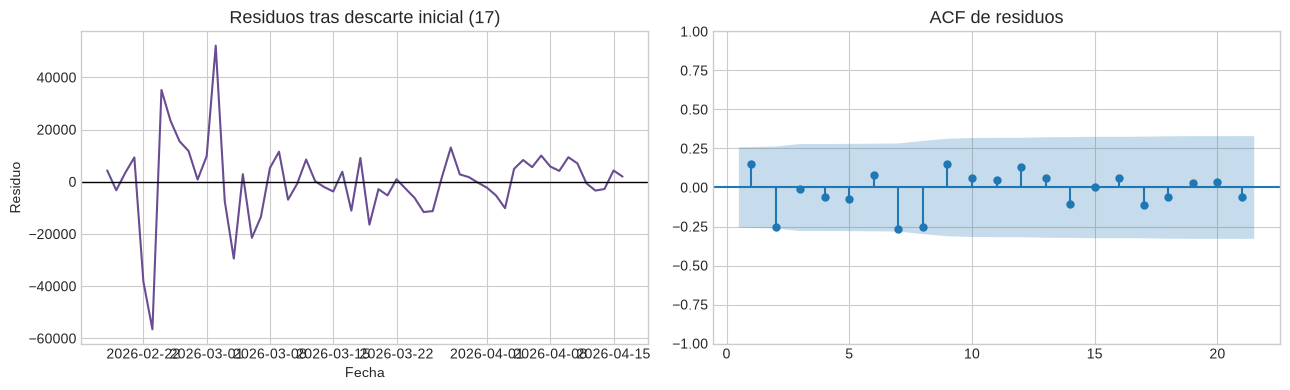

,estadístico,p-valor
7,11.2905,0.0459
14,20.1694,0.0639
21,22.4130,0.2642


In [10]:
resid = pd.Series(best_fit.resid, index=train.index).dropna()
burn = max(7, int(best_fit.loglikelihood_burn))
resid_diag = resid.iloc[burn:]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(resid_diag.index, resid_diag, color='#6A4C93')
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set(title=f'Residuos tras descarte inicial ({burn})', xlabel='Fecha', ylabel='Residuo')
plot_acf(resid_diag, lags=min(21, len(resid_diag) // 2 - 1), ax=axes[1], zero=False)
axes[1].set_title('ACF de residuos')
plt.tight_layout()
plt.show()

lb_lags = [7, 14, 21]
p, _, q = best_fit.model.order
P, _, Q, _ = best_fit.model.seasonal_order
ljung_box = acorr_ljungbox(resid_diag, lags=lb_lags, model_df=p + q + P + Q, return_df=True)
display(ljung_box.rename(columns={'lb_stat': 'estadístico', 'lb_pvalue': 'p-valor'}).round(4))

## 10. Evaluación walk-forward compacta

El holdout fijo mide un único origen de pronóstico y sus 14 horizontes mezclan dificultades distintas. Como complemento, hacemos 14 pronósticos de un paso: en cada fecha ampliamos el entrenamiento con los valores reales ya disponibles y reajustamos **la especificación previamente elegida**, manteniendo fija la selección de candidatos. Esto aproxima una operación con actualización diaria y sigue respetando el orden temporal. Para mantener una comparación directa, el MASE walk-forward usa la misma escala estacional obtenida únicamente del entrenamiento original.

In [11]:
selected_order, selected_seasonal = candidates[[f'SARIMA{o}x{s}' for o, s in candidates].index(best_label)]
history = train.copy()
walk_predictions = []
walk_started = time.perf_counter()

for date, actual in test.items():
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        walk_fit = SARIMAX(
            history, order=selected_order, seasonal_order=selected_seasonal,
            trend='c' if selected_order[1] == 0 else 'n',
            enforce_stationarity=False, enforce_invertibility=False,
        ).fit(disp=False, maxiter=150)
    walk_predictions.append(float(walk_fit.forecast(1).iloc[0]))
    history = pd.concat([history, pd.Series([actual], index=[date])]).asfreq('D')

pred_walk = pd.Series(walk_predictions, index=test.index, name='SARIMA walk-forward')
walk_scores = pd.DataFrame({
    'SARIMA fijo, varios horizontes': metrics(test, pred_sarima),
    'SARIMA walk-forward, h=1': metrics(test, pred_walk),
    'Naive estacional fijo': metrics(test, pred_snaive),
}).T
display(walk_scores.sort_values('MAE').round({'MAE': 1, 'RMSE': 1, 'MASE': 3}))
print(f'Tiempo walk-forward: {time.perf_counter() - walk_started:.2f} s para {H} reajustes')

,MAE,RMSE,MASE
Naive estacional fijo,5300.9,7058.6,0.457
"SARIMA walk-forward, h=1",5461.3,6741.1,0.471
"SARIMA fijo, varios horizontes",9388.8,11471.1,0.810


Tiempo walk-forward: 1.01 s para 14 reajustes


## 11. Interpretación y límites

La lectura final se basa en las tablas ejecutadas: el menor AIC identifica el candidato preferido dentro del conjunto pequeño, mientras que el menor error de test se establece mediante la evaluación reservada. Si el naive estacional obtiene menor MAE, RMSE o MASE, es el referente predictivo ganador en este período y ofrece la complejidad adecuada para este uso. Un MASE inferior a 1 indica que el error absoluto medio es menor que el del naive estacional de entrenamiento usado como escala; la comparación frente al naive del test se establece con las métricas calculadas sobre ese período.

**Qué sí aprendimos**

- La validación cronológica evita entrenar con el futuro.
- AIC sirve para comparar candidatos ajustados sobre los mismos datos; la evaluación fuera de muestra aporta la evidencia predictiva complementaria.
- El walk-forward muestra el desempeño a horizonte 1 con actualización diaria; responde una pregunta distinta del pronóstico fijo a 14 días.
- Los residuos y Ljung–Box revelan estructura que el promedio de error puede ocultar.

**Límites**

- Solo hay 89 días y un único bloque final de prueba; eventos de abril pueden dominar el resultado.
- La serie representa viajes reportados; estudiar demanda pendiente de atención, intención de viaje o población de pasajeros requiere fuentes adicionales.
- El modelo utiliza la historia de la serie. Incorporar clima, feriados, eventos, cambios regulatorios, flota disponible y calidad del sistema de reporte amplía el alcance explicativo.
- Los intervalos dependen de estabilidad temporal y de los supuestos del modelo.
- Para una decisión operativa conviene ampliar el histórico, usar varios orígenes temporales y comparar modelos con regresores exógenos conocidos al momento del pronóstico.

In [12]:
winner = score_table['MAE'].idxmin()
winner_mase = score_table['MASE'].idxmin()
coverage = ((test >= interval.iloc[:, 0]) & (test <= interval.iloc[:, 1])).mean()
print('Resumen reproducible')
print(f'- Modelo elegido por AIC de entrenamiento: {best_label} (AIC={best_fit.aic:.2f})')
print(f'- Menor MAE en test: {winner} ({score_table.loc[winner, "MAE"]:,.1f} viajes/día)')
print(f'- Escala MASE estacional m={MASE_M}: {mase_scale:,.1f} viajes/día, calculada solo con entrenamiento')
print(f'- Menor MASE en test fijo: {winner_mase} ({score_table.loc[winner_mase, "MASE"]:.3f})')
print(f'- MASE SARIMA fijo: {score_table.loc["SARIMA seleccionado", "MASE"]:.3f}; walk-forward: {walk_scores.loc["SARIMA walk-forward, h=1", "MASE"]:.3f}')
print(f'- Cobertura empírica del IC 90 % en 14 días: {coverage:.1%}')
print('- Objetivo: viajes reportados con recogida válida; la demanda pendiente de atención requiere evidencia adicional.')

Resumen reproducible
- Modelo elegido por AIC de entrenamiento: SARIMA(0, 1, 1)x(0, 1, 1, 7) (AIC=1287.84)
- Menor MAE en test: Naive estacional m=7 (5,300.9 viajes/día)
- Escala MASE estacional m=7: 11,592.3 viajes/día, calculada solo con entrenamiento
- Menor MASE en test fijo: Naive estacional m=7 (0.457)
- MASE SARIMA fijo: 0.810; walk-forward: 0.471
- Cobertura empírica del IC 90 % en 14 días: 100.0%
- Objetivo: viajes reportados con recogida válida; la demanda pendiente de atención requiere evidencia adicional.
